In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10


In [2]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

IMG_SIZE = (32, 32)
BATCH_SIZE = 64

train_path = "/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/cifar10/train"
test_path  = "/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/cifar10/test"

In [3]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 50000 files belonging to 10 classes.


I0000 00:00:1786551703.231749     405 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786551703.234116     405 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 10000 files belonging to 10 classes.


In [4]:
print(train_dataset)

for images, labels in train_dataset.take(1):
    print(images.shape)
    print(labels.shape)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
(64, 32, 32, 3)
(64,)


In [5]:
# Training data
X_train_list = []
y_train_list = []

for images, labels in train_dataset:
    X_train_list.append(images.numpy())
    y_train_list.append(labels.numpy())

X_train = np.concatenate(X_train_list, axis=0)
y_train = np.concatenate(y_train_list, axis=0)


# Testing data
X_test_list = []
y_test_list = []

for images, labels in test_dataset:
    X_test_list.append(images.numpy())
    y_test_list.append(labels.numpy())

X_test = np.concatenate(X_test_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)

In [6]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [7]:
print("Training Images :", X_train.shape)
print("Training Labels :", y_train.shape)
print("Testing Images  :", X_test.shape)
print("Testing Labels  :", y_test.shape)


Training Images : (50000, 32, 32, 3)
Training Labels : (50000,)
Testing Images  : (10000, 32, 32, 3)
Testing Labels  : (10000,)


In [8]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]


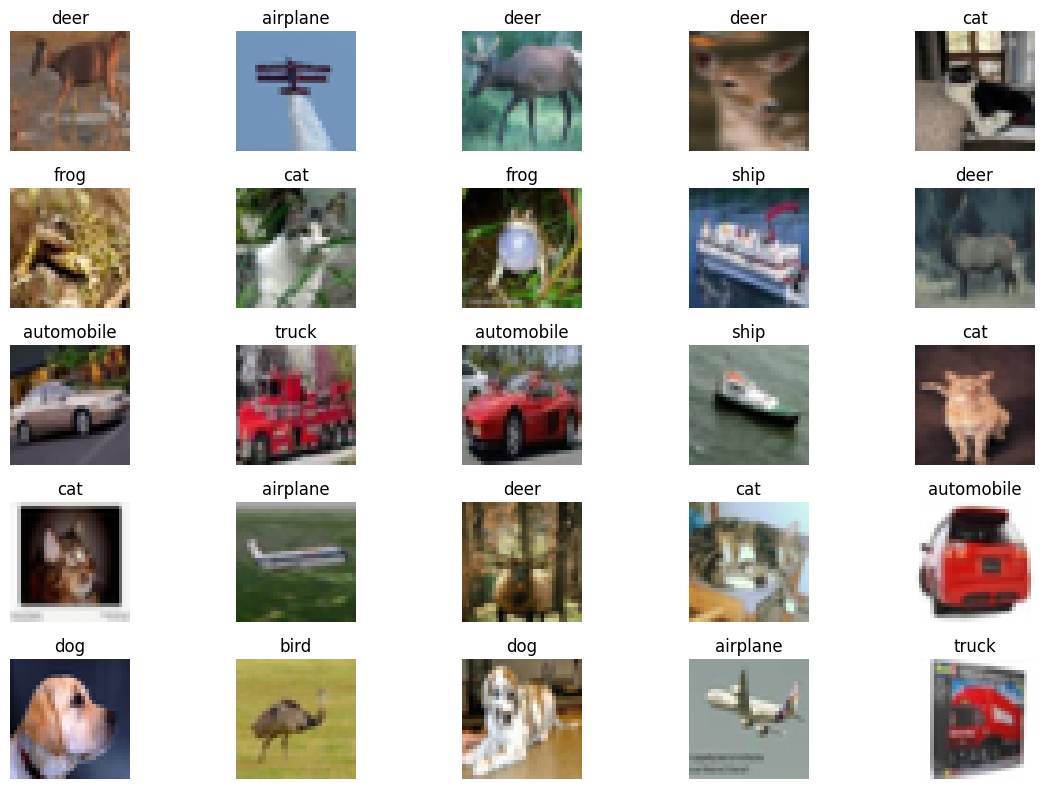

In [9]:
class_names = train_dataset.class_names

plt.figure(figsize=(12,8))

for images, labels in train_dataset.take(1):

    for i in range(25):
        plt.subplot(5,5,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

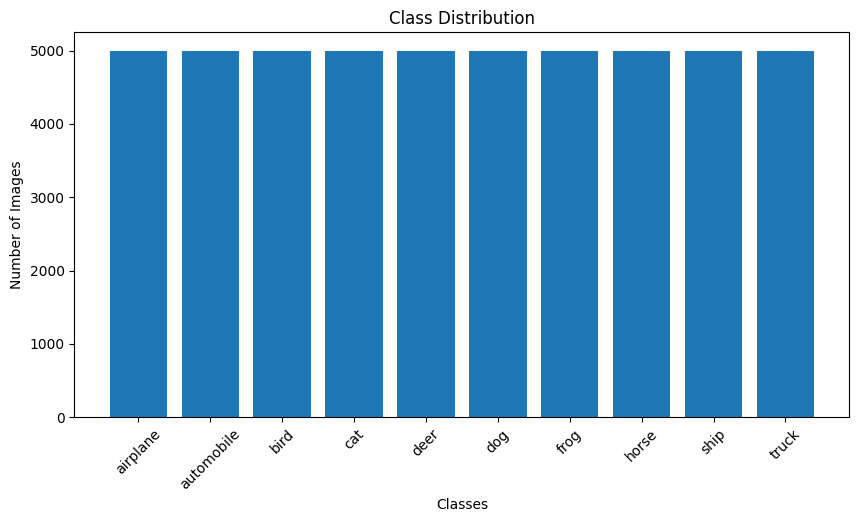

In [10]:
nique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10,5))

plt.bar(class_names, counts)

plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

In [11]:

print("\nNormalization Completed")
print("Pixel Range :", X_train.min(), "to", X_train.max())


Normalization Completed
Pixel Range : 0.0 to 1.0


In [12]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    AveragePooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.optimizers import Adam

In [13]:
model = Sequential()

# ---------------- First Convolution ----------------

model.add(

    Conv2D(

        filters=32,

        kernel_size=(3,3),

        strides=(1,1),

        padding="same",

        activation="relu",

        input_shape=(32,32,3)

    )

)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

# ---------------- Second Convolution ----------------

model.add(

    Conv2D(

        filters=64,

        kernel_size=(3,3),

        padding="same",

        activation="relu"

    )

)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

# ---------------- Third Convolution ----------------

model.add(

    Conv2D(

        filters=128,

        kernel_size=(3,3),

        padding="same",

        activation="relu"

    )

)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

# ---------------- Fully Connected ----------------

model.add(Flatten())

model.add(Dense(256,activation="relu"))

model.add(Dropout(0.5))

model.add(Dense(10,activation="softmax"))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(

    optimizer=Adam(learning_rate=0.001),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

In [15]:
model.build(input_shape=(None, 32, 32, 3))

In [16]:
print("\nCNN MODEL SUMMARY\n")

model.summary()


CNN MODEL SUMMARY



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 621,258 (2.37 MB)

 Trainable params: 620,810 (2.37 MB)

 Non-trainable params: 448 (1.75 KB)

In [17]:
feature_extractor = tf.keras.Model(
    inputs=model.inputs[0],
    outputs=model.layers[0].output
)

In [18]:
trainable_parameters = np.sum(

    [np.prod(v.shape) for v in model.trainable_weights]

)

print("\nTotal Trainable Parameters :",trainable_parameters)


Total Trainable Parameters : 620810


In [19]:
parameters = ((3*3*3)+1)*32

print("\nManual Parameter Calculation (First Conv Layer)")

print("((3×3×3)+1)×32 =",parameters)


Manual Parameter Calculation (First Conv Layer)
((3×3×3)+1)×32 = 896


In [20]:
def output_size(N,F,P,S):

    return ((N-F+2*P)//S)+1

print("\nOutput Feature Map Size")

print("Input Size : 32")

print("Kernel : 3")

print("Stride : 1")

print("Padding : 1")

print("Output Size :",output_size(32,3,1,1))


Output Feature Map Size
Input Size : 32
Kernel : 3
Stride : 1
Padding : 1
Output Size : 32


task 2


In [21]:
from tensorflow.keras.models import Model

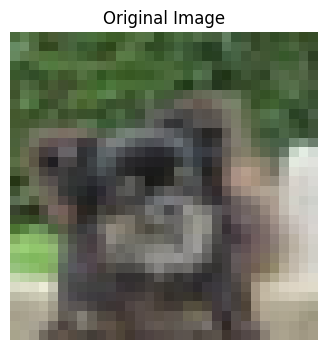

In [22]:
sample = X_train[0]

plt.figure(figsize=(4,4))
plt.imshow(sample)
plt.title("Original Image")
plt.axis("off")
plt.show()

sample = np.expand_dims(sample,axis=0)

Kernel Size : 3 x 3


I0000 00:00:1786551916.389025     478 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Output Shape : (1, 32, 32, 8)


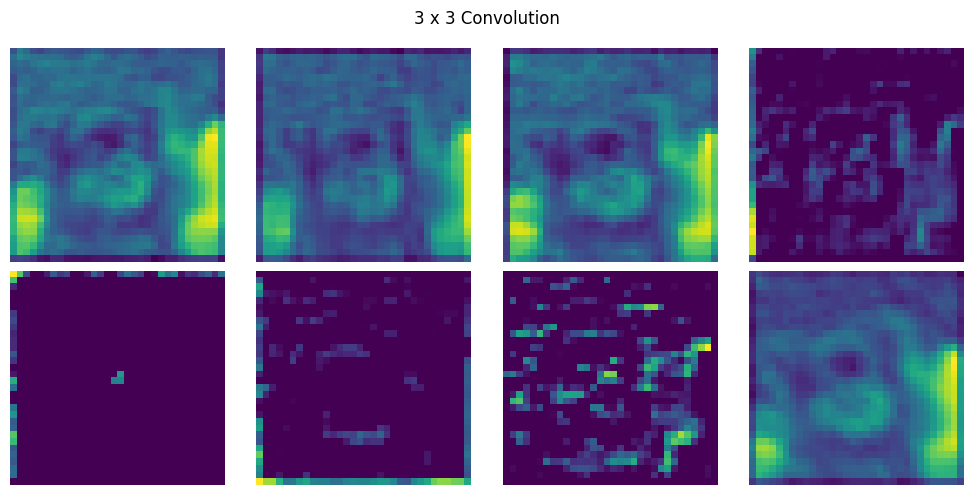

Kernel Size : 5 x 5
Output Shape : (1, 32, 32, 8)


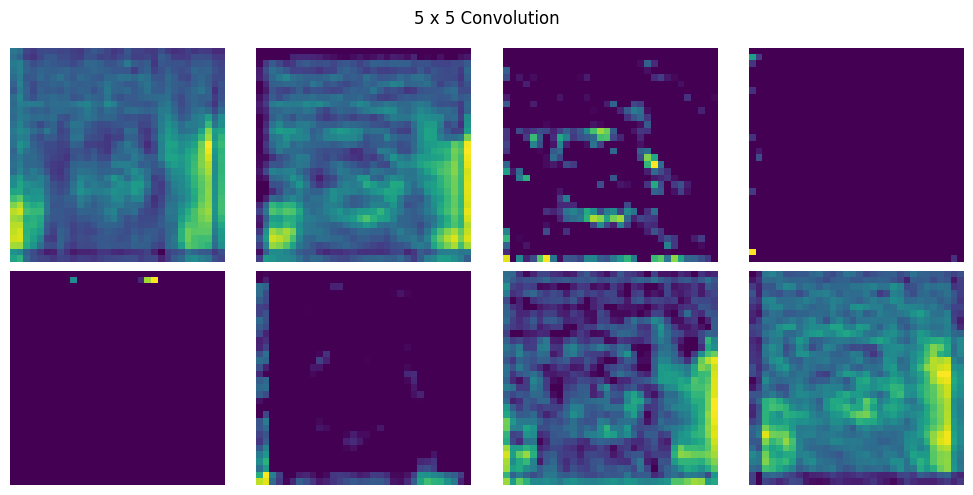

Kernel Size : 7 x 7
Output Shape : (1, 32, 32, 8)


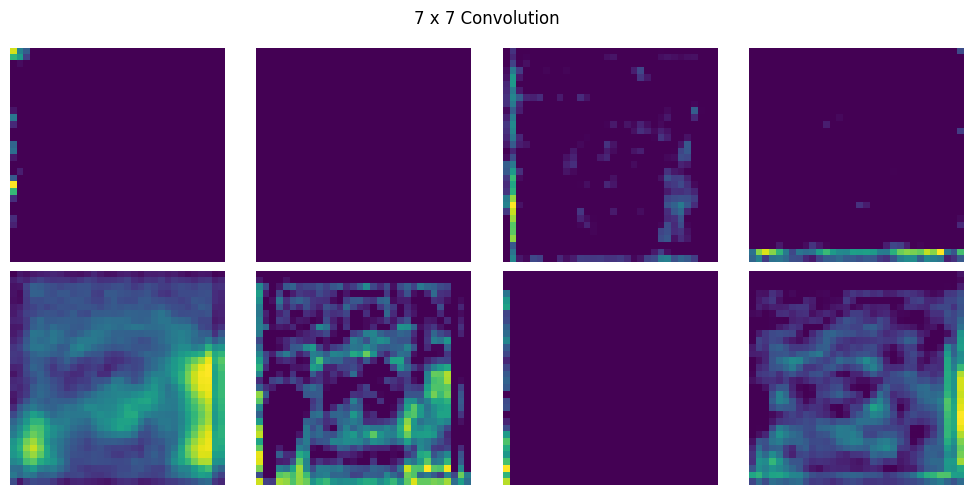

In [23]:
kernel_sizes=[3,5,7]

for kernel in kernel_sizes:

    print(f"Kernel Size : {kernel} x {kernel}")

    kernel_model=Sequential([
        tf.keras.Input(shape=(32,32,3)),

        Conv2D(
            filters=8,
            kernel_size=(kernel,kernel),
            padding="same",
            activation="relu"
        )
    ])

    feature_maps=kernel_model.predict(sample,verbose=0)

    print("Output Shape :",feature_maps.shape)

    plt.figure(figsize=(10,5))

    for i in range(8):

        plt.subplot(2,4,i+1)

        plt.imshow(feature_maps[0,:,:,i],cmap="viridis")

        plt.axis("off")

    plt.suptitle(f"{kernel} x {kernel} Convolution")

    plt.tight_layout()

    plt.show()

In [24]:
print("STRIDE COMPARISON")
for stride in [1,2]:

    stride_model=Sequential([

        tf.keras.Input(shape=(32,32,3)),

        Conv2D(
            filters=8,
            kernel_size=(3,3),
            strides=(stride,stride),
            padding="same",
            activation="relu"
        )

    ])

    output=stride_model.predict(sample,verbose=0)

    print("Stride =",stride)

    print("Output Shape :",output.shape)

STRIDE COMPARISON
Stride = 1
Output Shape : (1, 32, 32, 8)
Stride = 2
Output Shape : (1, 16, 16, 8)


In [25]:
print("PADDING COMPARISON")
for padding in ["same","valid"]:

    padding_model=Sequential([

        tf.keras.Input(shape=(32,32,3)),

        Conv2D(
            filters=8,
            kernel_size=(3,3),
            padding=padding,
            activation="relu"
        )

    ])

    output=padding_model.predict(sample,verbose=0)

    print("Padding :",padding)

    print("Output Shape :",output.shape)

PADDING COMPARISON
Padding : same
Output Shape : (1, 32, 32, 8)
Padding : valid
Output Shape : (1, 30, 30, 8)


In [26]:
def output_size(n,f,p,s):

    return ((n-f+2*p)//s)+1

print("OUTPUT DIMENSION CALCULATIONS")

print("3x3 Kernel")
print(output_size(32,3,1,1))

print()

print("5x5 Kernel")
print(output_size(32,5,2,1))

print()

print("7x7 Kernel")
print(output_size(32,7,3,1))

print()

print("Stride = 2")

print(output_size(32,3,1,2))

OUTPUT DIMENSION CALCULATIONS
3x3 Kernel
32

5x5 Kernel
32

7x7 Kernel
32

Stride = 2
16


FEATURE MAP VISUALIZATION
Feature Map Shape : (1, 32, 32, 32)


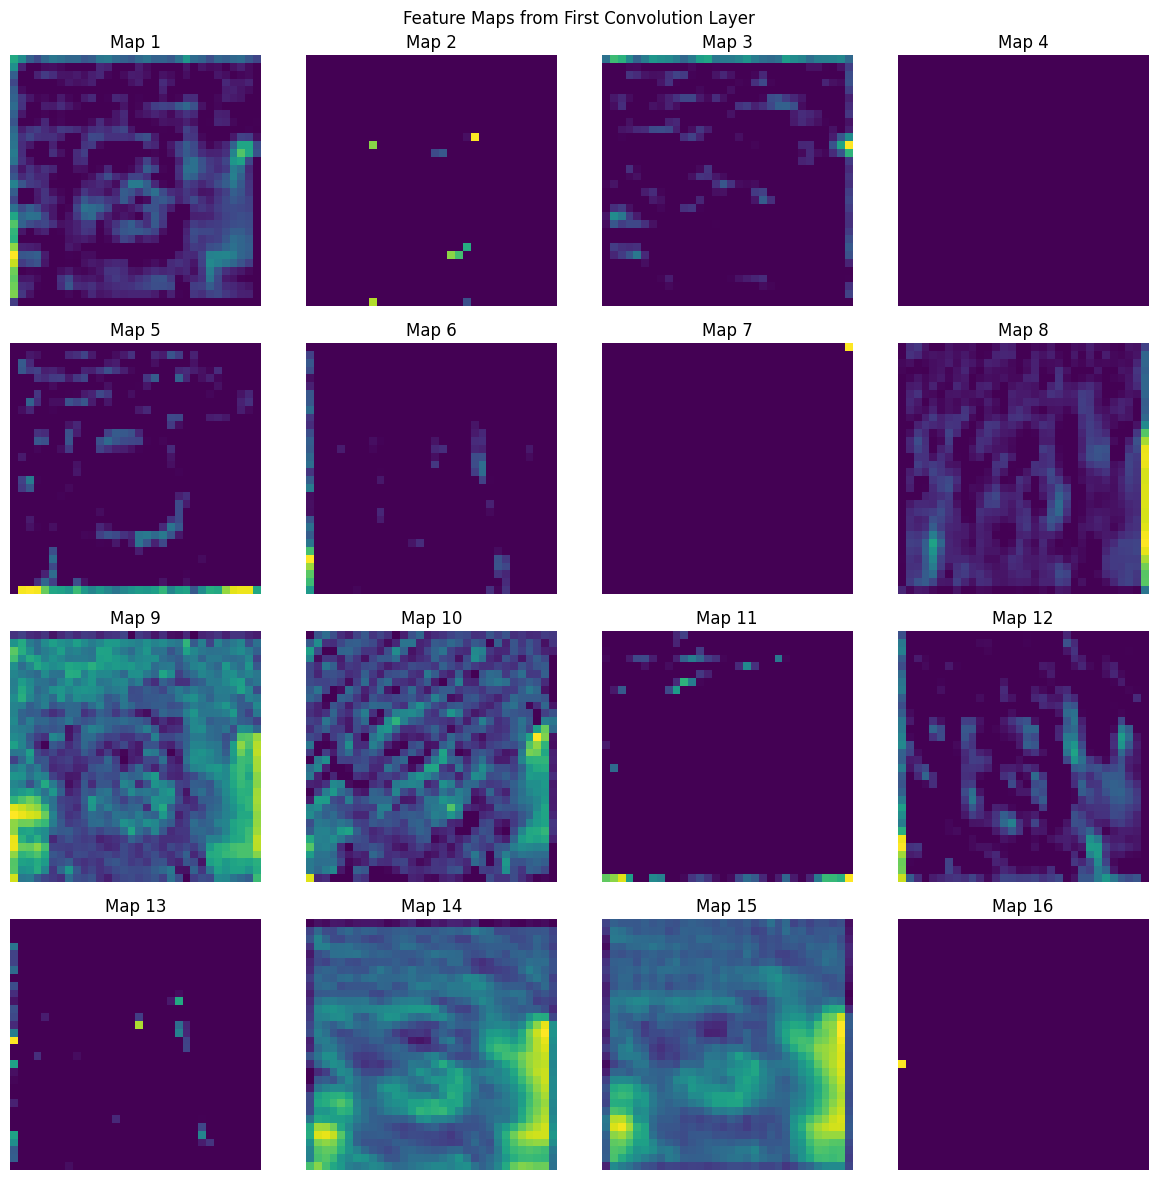

In [27]:

print("FEATURE MAP VISUALIZATION")

feature_model=tf.keras.Model(

    inputs=model.inputs,

    outputs=model.layers[0].output

)

feature_maps=feature_model.predict(sample,verbose=0)

print("Feature Map Shape :",feature_maps.shape)

plt.figure(figsize=(12,12))

for i in range(16):

    plt.subplot(4,4,i+1)

    plt.imshow(feature_maps[0,:,:,i],cmap="viridis")

    plt.axis("off")

    plt.title("Map "+str(i+1))

plt.suptitle("Feature Maps from First Convolution Layer")

plt.tight_layout()

plt.show()


In [28]:
print("\nStatistics")

print("Minimum :",np.min(feature_maps))

print("Maximum :",np.max(feature_maps))

print("Mean    :",np.mean(feature_maps))

print("Std Dev :",np.std(feature_maps))


Statistics
Minimum : 0.0
Maximum : 0.6540749
Mean    : 0.037609316
Std Dev : 0.069472186


Task 5

In [29]:

max_model = Sequential([

    tf.keras.Input(shape=(32,32,3)),

    Conv2D(16,(3,3),padding="same",activation="relu"),

    MaxPooling2D(pool_size=(2,2))

])


In [30]:
avg_model = Sequential([

    tf.keras.Input(shape=(32,32,3)),

    Conv2D(16,(3,3),padding="same",activation="relu"),

    AveragePooling2D(pool_size=(2,2))

])

sample = np.expand_dims(X_train[0],axis=0)

max_output = max_model.predict(sample,verbose=0)

avg_output = avg_model.predict(sample,verbose=0)

print("Max Pool Output Shape :",max_output.shape)

print("Average Pool Output Shape :",avg_output.shape)


Max Pool Output Shape : (1, 16, 16, 16)
Average Pool Output Shape : (1, 16, 16, 16)


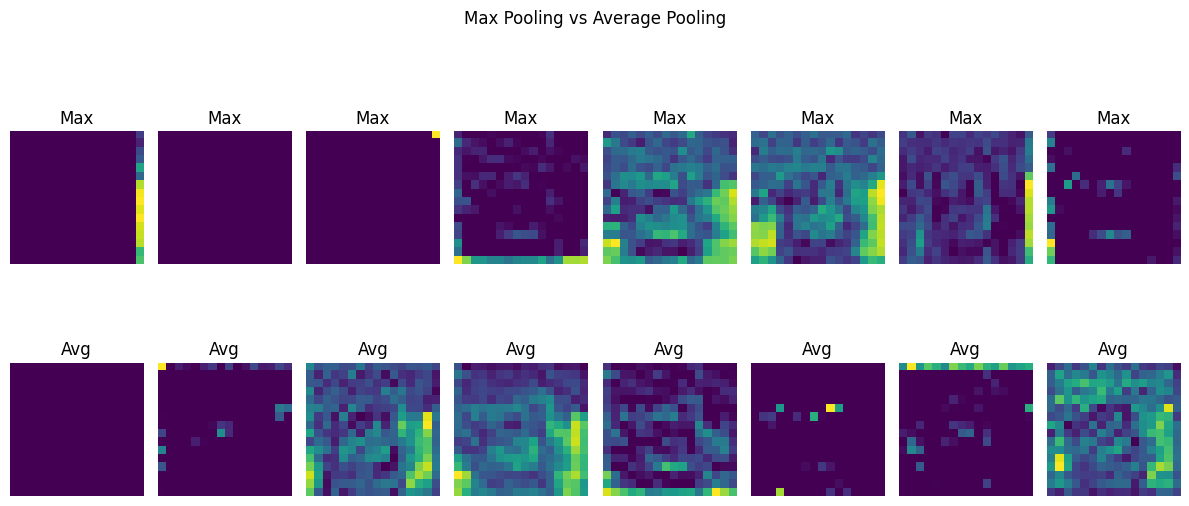

In [31]:
plt.figure(figsize=(12,6))

for i in range(8):

    plt.subplot(2,8,i+1)

    plt.imshow(max_output[0,:,:,i],cmap="viridis")

    plt.title("Max")

    plt.axis("off")

for i in range(8):

    plt.subplot(2,8,i+9)

    plt.imshow(avg_output[0,:,:,i],cmap="viridis")

    plt.title("Avg")

    plt.axis("off")

plt.suptitle("Max Pooling vs Average Pooling")

plt.tight_layout()

plt.show()


In [32]:
print("MODEL TRAINING")
history = model.fit(

    X_train,

    y_train,

    epochs=20,

    batch_size=32,

    validation_split=0.2,

    verbose=1

)

MODEL TRAINING
Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.4391 - loss: 1.5810 - val_accuracy: 0.5509 - val_loss: 1.2578
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5728 - loss: 1.2028 - val_accuracy: 0.6076 - val_loss: 1.0899
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6438 - loss: 1.0242 - val_accuracy: 0.4637 - val_loss: 1.7678
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6845 - loss: 0.9086 - val_accuracy: 0.6919 - val_loss: 0.9010
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7186 - loss: 0.8154 - val_accuracy: 0.6974 - val_loss: 0.8907
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7470 - loss: 0.7395 - val_accuracy: 0.6900 - val_loss: 0.9234
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7659 - loss: 0.6790 - val_accuracy: 0.7338 - val_loss: 0.7906
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7869 -

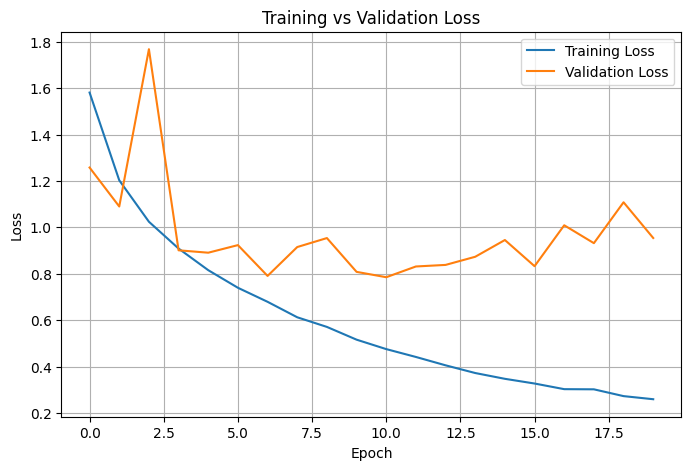

In [33]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"],label="Training Loss")

plt.plot(history.history["val_loss"],label="Validation Loss")

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()


In [34]:
print("\nFinal Training Accuracy :")

print(history.history["accuracy"][-1])

print("\nFinal Validation Accuracy :")

print(history.history["val_accuracy"][-1])


Final Training Accuracy :
0.911050021648407

Final Validation Accuracy :
0.7641000151634216


In [35]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [36]:

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("\nTest Loss :", test_loss)
print("Test Accuracy :", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7628 - loss: 0.9728

Test Loss : 0.9728477597236633
Test Accuracy : 0.7627999782562256


In [37]:
y_pred_prob = model.predict(X_test, verbose=1)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = y_test.flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [38]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("PERFORMANCE METRICS")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

PERFORMANCE METRICS
Accuracy  : 0.7628
Precision : 0.7642
Recall    : 0.7628
F1 Score  : 0.7605


In [39]:
print("CLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane       0.68      0.86      0.76      1000
  automobile       0.85      0.91      0.88      1000
        bird       0.63      0.70      0.66      1000
         cat       0.65      0.50      0.56      1000
        deer       0.77      0.68      0.72      1000
         dog       0.72      0.67      0.69      1000
        frog       0.79      0.85      0.82      1000
       horse       0.84      0.79      0.81      1000
        ship       0.89      0.81      0.85      1000
       truck       0.84      0.85      0.84      1000

    accuracy                           0.76     10000
   macro avg       0.76      0.76      0.76     10000
weighted avg       0.76      0.76      0.76     10000



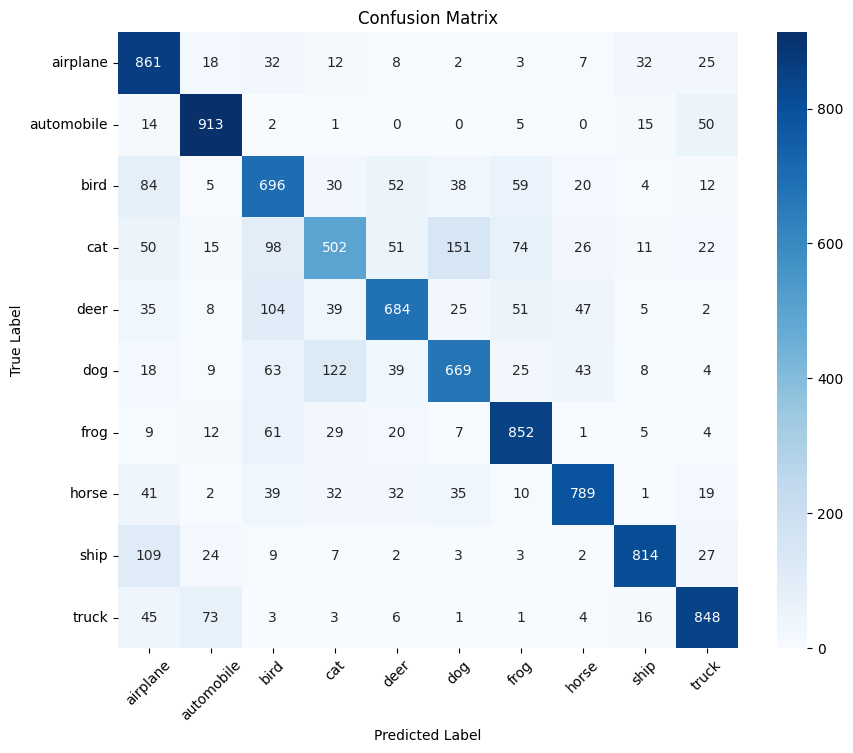

In [40]:
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.xticks(rotation=45)

plt.yticks(rotation=0)

plt.show()


In [41]:
print(X_test.shape)
print(X_test.dtype)

print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

(10000, 32, 32, 3)
float32
Minimum: 0.0
Maximum: 1.0


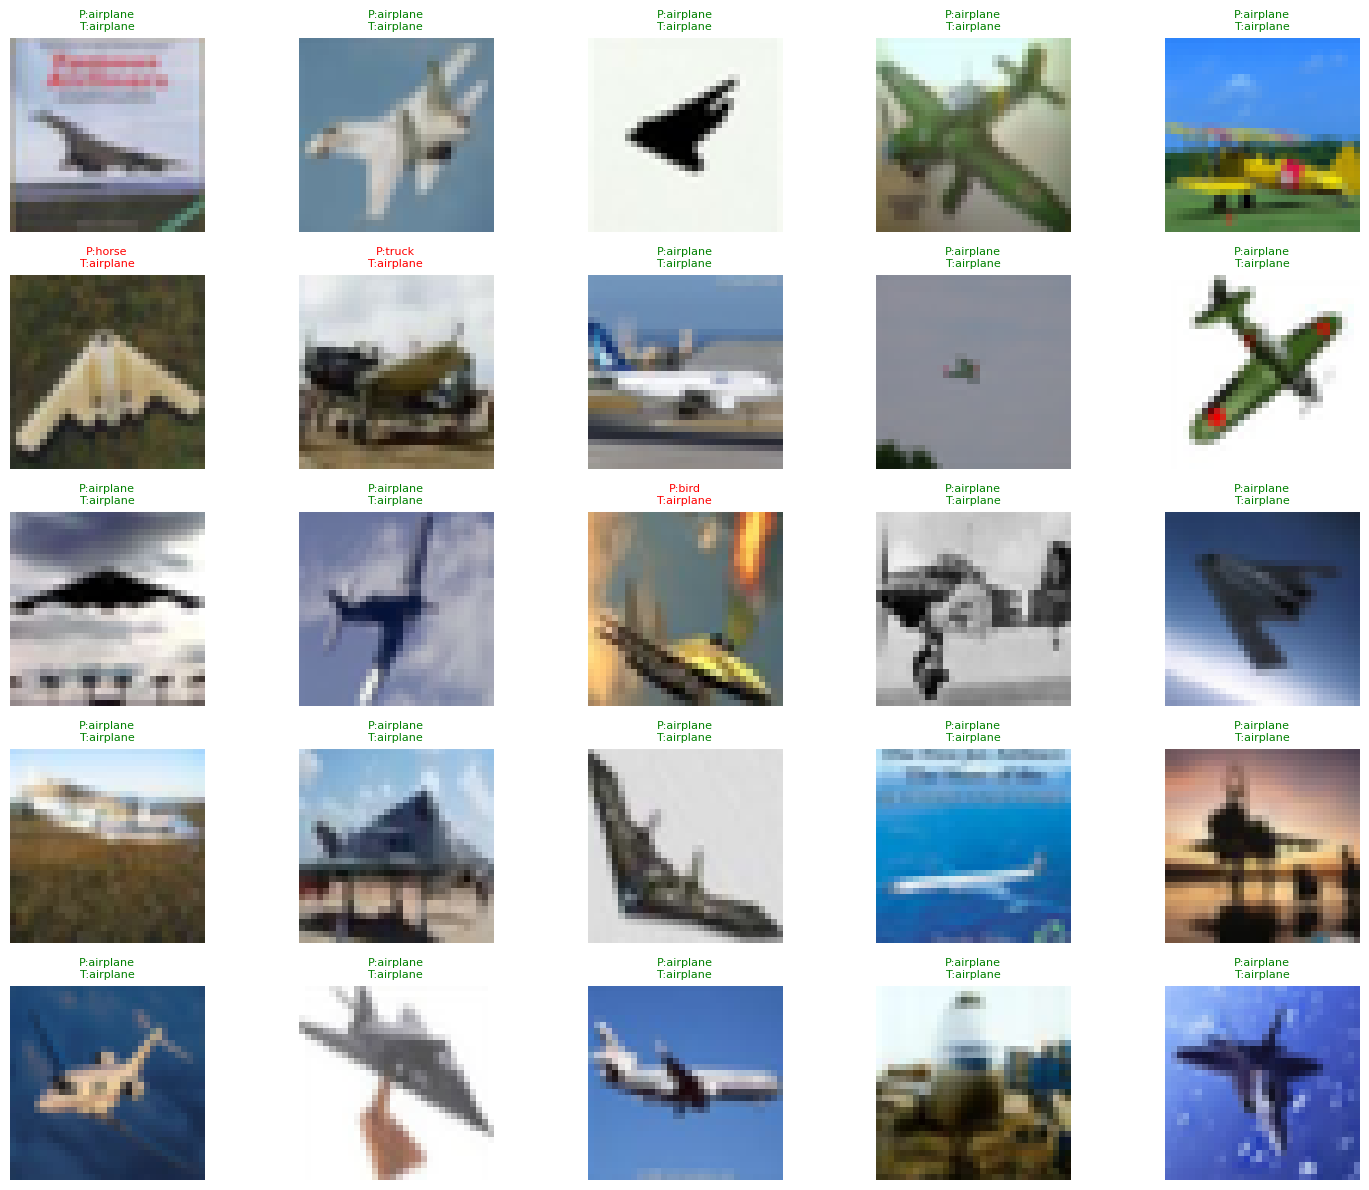

In [42]:

plt.figure(figsize=(15,12))

for i in range(25):

    plt.subplot(5,5,i+1)

    plt.imshow(X_test[i])

    pred = class_names[y_pred[i]]

    true = class_names[y_true[i]]

    if pred == true:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"P:{pred}\nT:{true}",
        fontsize=8,
        color=color
    )

    plt.axis("off")

plt.tight_layout()

plt.show()


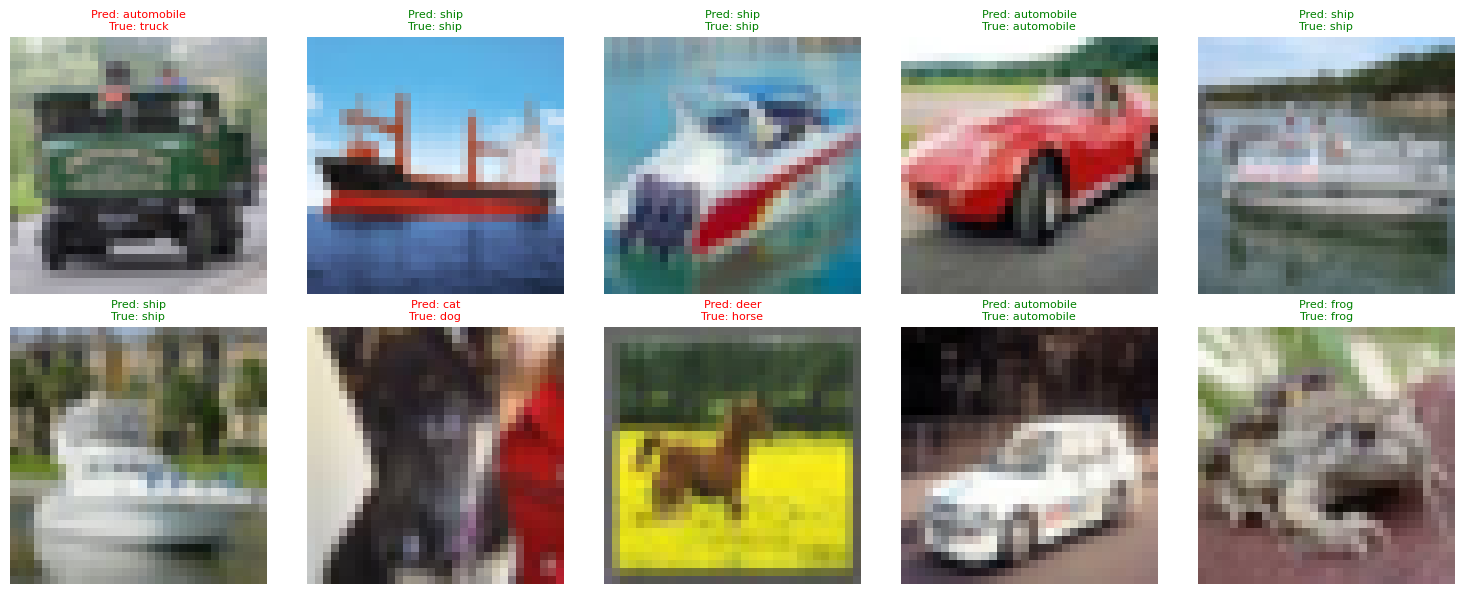

In [43]:
random_indices = np.random.choice(len(X_test), 10, replace=False)

plt.figure(figsize=(15,6))

for i, idx in enumerate(random_indices):

    plt.subplot(2,5,i+1)

    plt.imshow(X_test[idx])

    pred = class_names[y_pred[idx]]

    true = class_names[y_true[idx]]

    if pred == true:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Pred: {pred}\nTrue: {true}",
        fontsize=8,
        color=color
    )

    plt.axis("off")

plt.tight_layout()

plt.show()


In [44]:

print("MODEL INFORMATION")

print("Optimizer          : Adam")

print("Loss Function      : Sparse Categorical Crossentropy")

print("Epochs             :", len(history.history["accuracy"]))

print("Batch Size         : 32")

print("Input Shape        :", X_train.shape[1:])

print("Number of Classes  :", len(class_names))

print("Trainable Params   :", model.count_params())


MODEL INFORMATION
Optimizer          : Adam
Loss Function      : Sparse Categorical Crossentropy
Epochs             : 20
Batch Size         : 32
Input Shape        : (32, 32, 3)
Number of Classes  : 10
Trainable Params   : 621258


In [45]:
print("EXPERIMENT SUMMARY")
print(f"Training Accuracy      : {history.history['accuracy'][-1]:.4f}")
print(f"Validation Accuracy    : {history.history['val_accuracy'][-1]:.4f}")
print(f"Testing Accuracy       : {accuracy:.4f}")
print(f"Weighted Precision     : {precision:.4f}")
print(f"Weighted Recall        : {recall:.4f}")
print(f"Weighted F1 Score      : {f1:.4f}")


EXPERIMENT SUMMARY
Training Accuracy      : 0.9111
Validation Accuracy    : 0.7641
Testing Accuracy       : 0.7628
Weighted Precision     : 0.7642
Weighted Recall        : 0.7628
Weighted F1 Score      : 0.7605


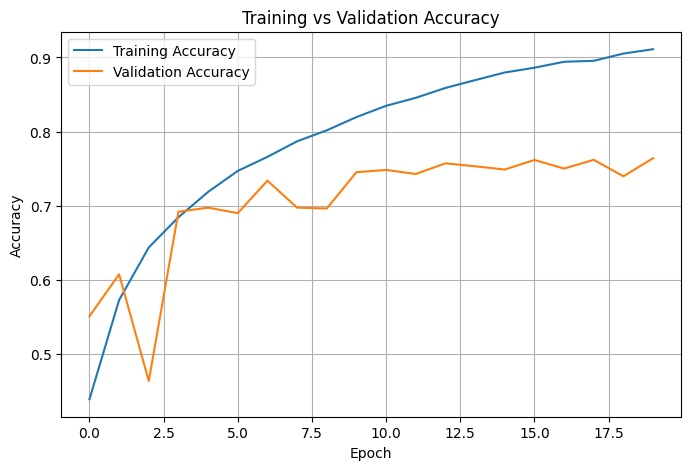

In [46]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


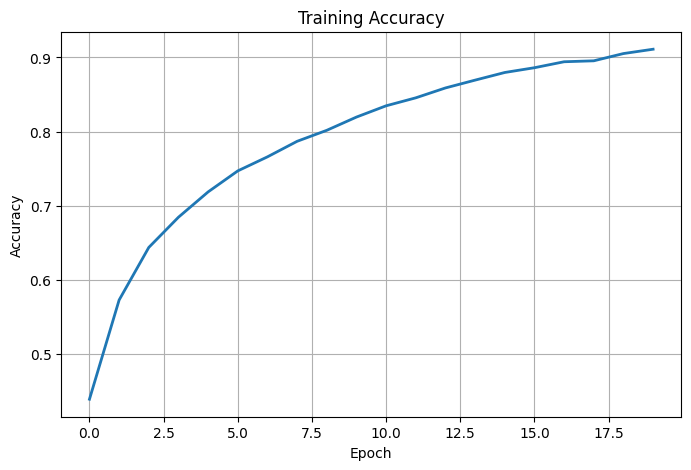

In [47]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], linewidth=2)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()

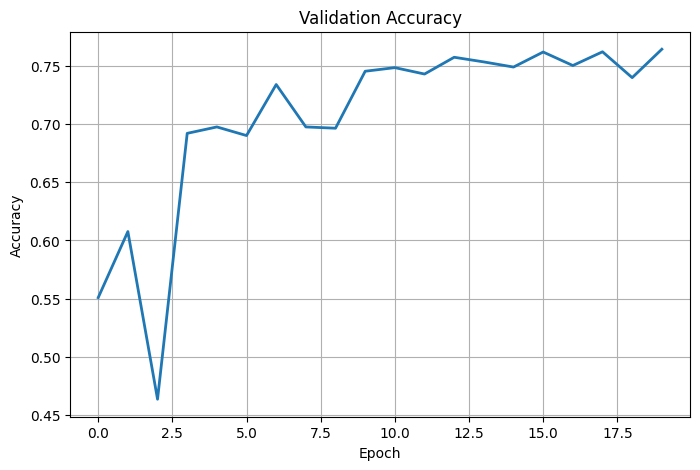

In [48]:
plt.figure(figsize=(8,5))

plt.plot(history.history['val_accuracy'], linewidth=2)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()

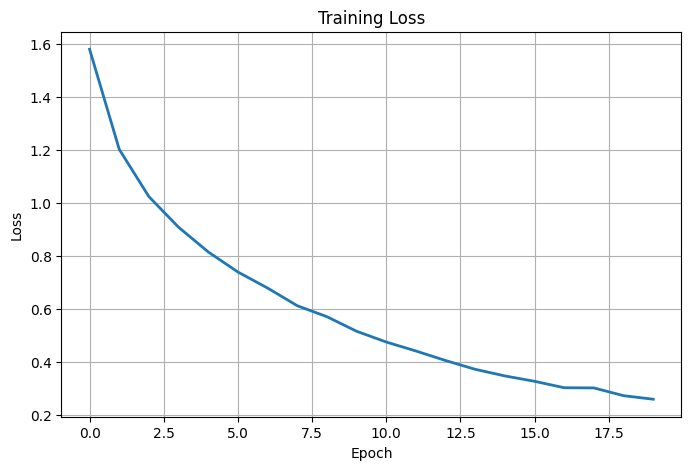

In [49]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], linewidth=2)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

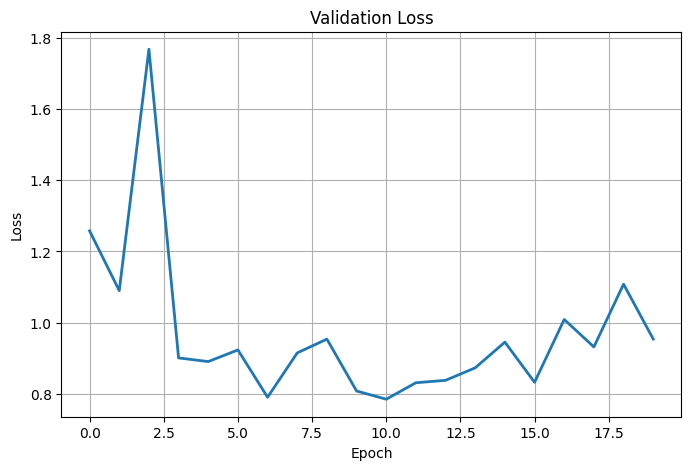

In [50]:
plt.figure(figsize=(8,5))

plt.plot(history.history['val_loss'], linewidth=2)

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

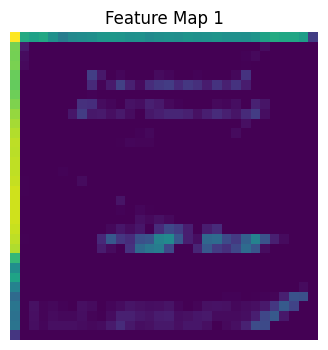

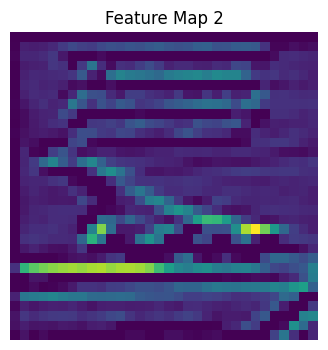

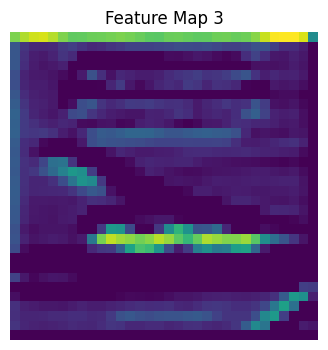

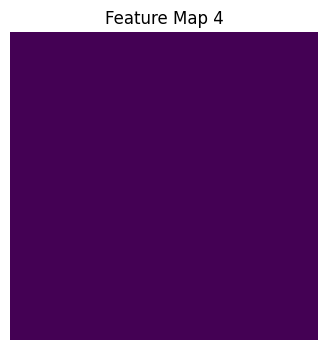

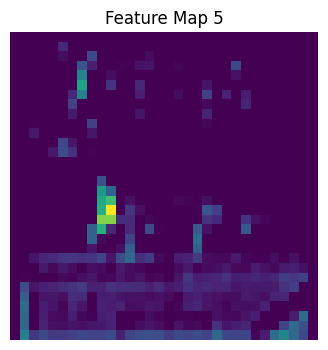

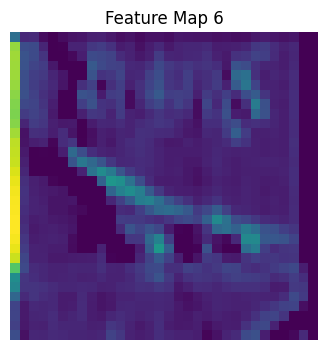

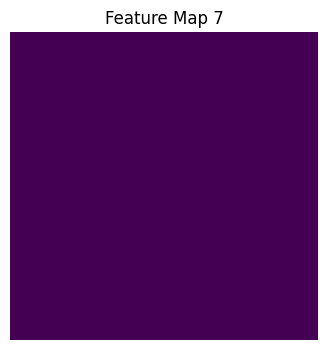

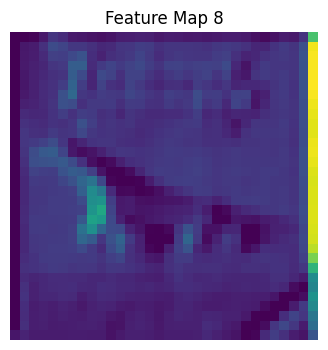

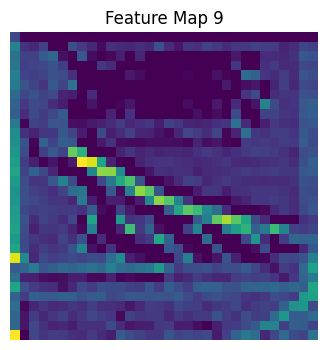

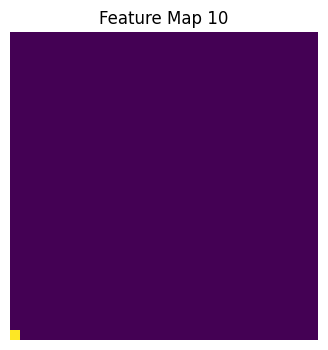

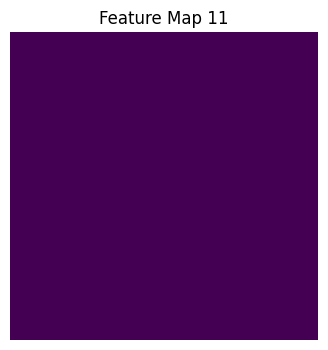

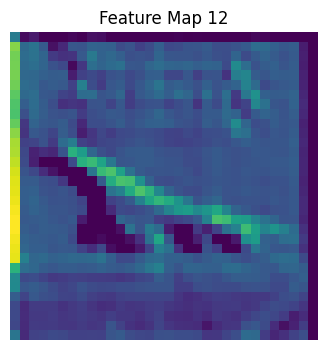

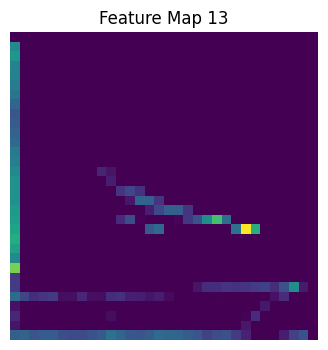

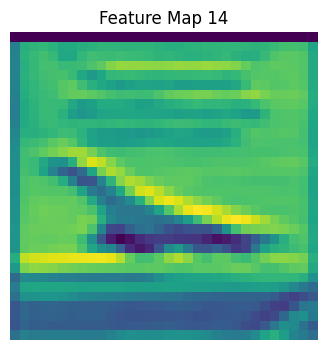

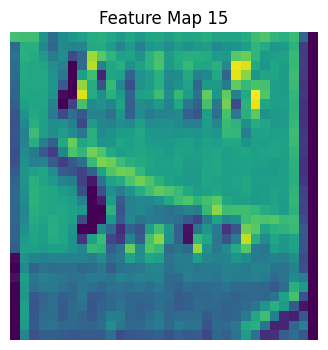

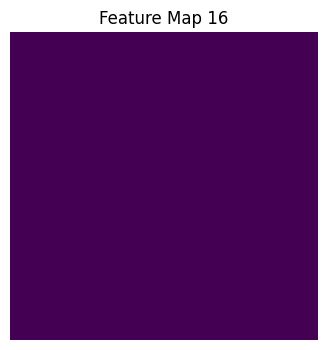

In [51]:
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)

sample = np.expand_dims(X_test[0], axis=0)

feature_maps = feature_model.predict(sample, verbose=0)

for i in range(16):

    plt.figure(figsize=(4,4))

    plt.imshow(feature_maps[0,:,:,i], cmap="viridis")

    plt.title(f"Feature Map {i+1}")

    plt.axis("off")

    plt.show()

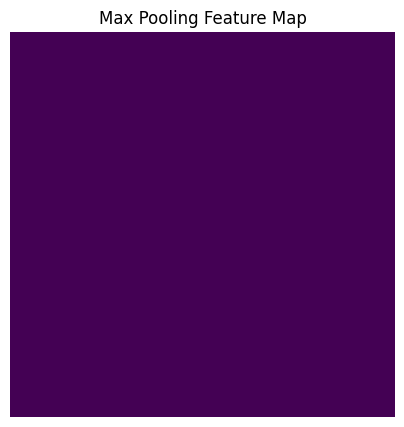

In [52]:
max_model = Sequential([
    tf.keras.Input(shape=(32,32,3)),
    Conv2D(16,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2))
])

sample = np.expand_dims(X_train[0],axis=0)

max_output = max_model.predict(sample,verbose=0)

plt.figure(figsize=(5,5))
plt.imshow(max_output[0,:,:,0], cmap='viridis')
plt.title("Max Pooling Feature Map")
plt.axis("off")
plt.show()

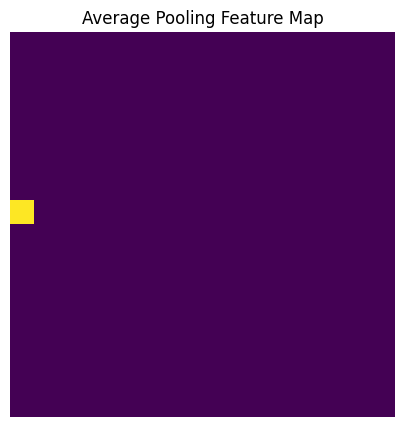

In [53]:
avg_model = Sequential([
    tf.keras.Input(shape=(32,32,3)),
    Conv2D(16,(3,3),activation='relu',padding='same'),
    AveragePooling2D((2,2))
])

avg_output = avg_model.predict(sample,verbose=0)

plt.figure(figsize=(5,5))
plt.imshow(avg_output[0,:,:,0], cmap='viridis')
plt.title("Average Pooling Feature Map")
plt.axis("off")
plt.show()

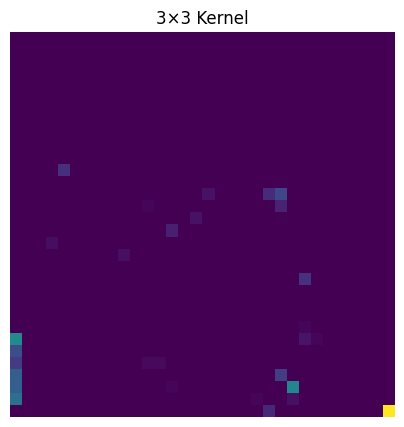

In [54]:
kernel3 = Sequential([
    tf.keras.Input(shape=(32,32,3)),
    Conv2D(8,(3,3),activation='relu',padding='same')
])

out = kernel3.predict(sample,verbose=0)

plt.figure(figsize=(5,5))
plt.imshow(out[0,:,:,0], cmap='viridis')
plt.title("3×3 Kernel")
plt.axis("off")
plt.show()

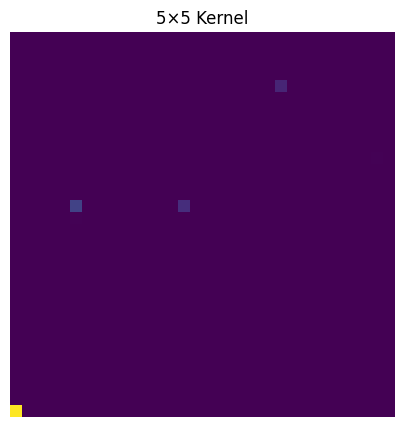

In [55]:
kernel5 = Sequential([
    tf.keras.Input(shape=(32,32,3)),
    Conv2D(8,(5,5),activation='relu',padding='same')
])

out = kernel5.predict(sample,verbose=0)

plt.figure(figsize=(5,5))
plt.imshow(out[0,:,:,0], cmap='viridis')
plt.title("5×5 Kernel")
plt.axis("off")
plt.show()

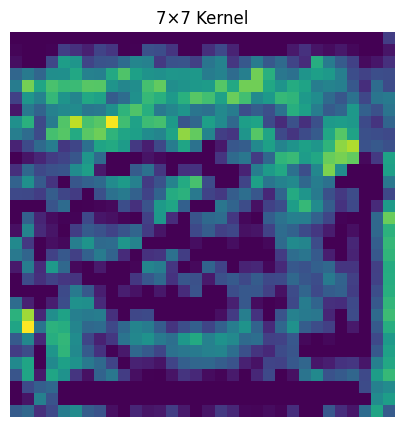

In [56]:
kernel7 = Sequential([
    tf.keras.Input(shape=(32,32,3)),
    Conv2D(8,(7,7),activation='relu',padding='same')
])

out = kernel7.predict(sample,verbose=0)

plt.figure(figsize=(5,5))
plt.imshow(out[0,:,:,0], cmap='viridis')
plt.title("7×7 Kernel")
plt.axis("off")
plt.show()

In [57]:
model = Sequential()

model.add(Conv2D(32,(3,3),activation='relu',padding='same',
                 input_shape=(32,32,3)))

model.add(BatchNormalization())

model.add(AveragePooling2D(pool_size=(2,2)))

model.add(Conv2D(64,(3,3),activation='relu',padding='same'))

model.add(BatchNormalization())

model.add(AveragePooling2D(pool_size=(2,2)))

model.add(Conv2D(128,(3,3),activation='relu',padding='same'))

model.add(BatchNormalization())

model.add(AveragePooling2D(pool_size=(2,2)))

model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10,activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [58]:
model.compile(

    optimizer=Adam(learning_rate=0.001),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

In [59]:
history_avg = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.4662 - loss: 1.5131 - val_accuracy: 0.5734 - val_loss: 1.2022
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6152 - loss: 1.0913 - val_accuracy: 0.6245 - val_loss: 1.0396
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6841 - loss: 0.9036 - val_accuracy: 0.6742 - val_loss: 0.9283
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7262 - loss: 0.7838 - val_accuracy: 0.7011 - val_loss: 0.8477
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7623 - loss: 0.6821 - val_accuracy: 0.7044 - val_loss: 0.8442
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7908 - loss: 0.5946 - val_accuracy: 0.7246 - val_loss: 0.8200
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8144 - loss: 0.5229 - val_accuracy: 0.7413 - val_loss: 0.7851
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8378 - loss: 0.4632 -

In [60]:
print("Max Pool Accuracy :", history.history['val_accuracy'][-1])
print("Average Pool Accuracy :", history_avg.history['val_accuracy'][-1])

Max Pool Accuracy : 0.7641000151634216
Average Pool Accuracy : 0.7734000086784363
